# Object recognition with visual words

Can local SIFT descriptors support classification without a learned image encoder?

I build a vocabulary on training images and compare visual-word histograms with a simple resized-pixel baseline. This establishes a classical reference before the CNN projects.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import seed_everything

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "03_visual_words"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Course object categories

Import the supplied archive with `python scripts/prepare_course_data.py '/path/Computer Vision.zip'`. This notebook uses its four object categories. The short run caps each category at 35 images; the full run uses up to 200. Filenames are sorted before deterministic sampling.

In [5]:
import cv2
from sklearn.cluster import MiniBatchKMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

directory = root / "data" / "course" / "4_ObjectCategories"
if not directory.exists():
    raise FileNotFoundError(
        "Import Computer Vision.zip with scripts/prepare_course_data.py"
    )
images, labels, names = [], [], []
for label, folder in enumerate(sorted(p for p in directory.iterdir() if p.is_dir())):
    names.append(folder.name)
    paths = sorted(folder.glob("*.jpg"))
    chosen = np.random.default_rng(1031).choice(
        len(paths), min(len(paths), 35 if QUICK else 200), replace=False
    )
    for index in chosen:
        image = cv2.imread(str(paths[index]), cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise ValueError(f"Unreadable image: {paths[index].name}")
        images.append(cv2.resize(image, (128, 128)))
        labels.append(label)
labels = np.asarray(labels)
development, test_ids = train_test_split(
    np.arange(len(labels)), test_size=0.2, stratify=labels, random_state=1031
)
train_ids, validation_ids = train_test_split(
    development, test_size=0.25, stratify=labels[development], random_state=1031
)
print(names, len(train_ids), len(validation_ids), len(test_ids))

['airplanes', 'cars', 'faces', 'motorbikes'] 480 160 160


## Training vocabulary

Each descriptor has 128 dimensions. K-means assigns them to visual words; the histogram discards location. The vocabulary is fitted on training descriptors only. I cap the descriptor pool so one highly textured image cannot dominate memory use.

In [7]:
sift = cv2.SIFT_create(nfeatures=150)
descriptors = []
for image in images:
    _, values = sift.detectAndCompute(image, None)
    descriptors.append(
        values if values is not None else np.empty((0, 128), dtype=np.float32)
    )
training_descriptors = np.concatenate([descriptors[i] for i in train_ids])
if len(training_descriptors) < 32:
    raise ValueError("Too few SIFT descriptors for 32 visual words")
vocabulary = MiniBatchKMeans(n_clusters=32, random_state=1031, n_init=3, batch_size=512)
vocabulary.fit(training_descriptors[:20000])


def histogram(values):
    counts = (
        np.bincount(vocabulary.predict(values), minlength=32)
        if len(values)
        else np.zeros(32)
    )
    frequencies = counts / max(counts.sum(), 1)
    return np.sqrt(frequencies)


features = np.stack([histogram(values) for values in descriptors])
pixels = np.stack([cv2.resize(image, (16, 16)).ravel() / 255 for image in images])
print(
    features.shape,
    "images without descriptors:",
    sum(len(value) == 0 for value in descriptors),
)

(800, 32) images without descriptors: 0


## Validation and final comparison

Regularization is selected independently for each representation using validation macro F1. Square-root histograms reduce the influence of frequent words. The selected models are evaluated on the same untouched test subset.

In [9]:
rows = []
fitted = {}
for name, representation in {"pixels": pixels, "visual_words": features}.items():
    candidates = []
    for regularization in [0.1, 1, 10]:
        classifier = LogisticRegression(
            C=regularization, max_iter=1500, random_state=1031
        )
        classifier.fit(representation[train_ids], labels[train_ids])
        score = f1_score(
            labels[validation_ids],
            classifier.predict(representation[validation_ids]),
            average="macro",
        )
        candidates.append((score, regularization, classifier))
    validation_f1, regularization, classifier = max(
        candidates, key=lambda item: item[0]
    )
    predictions = classifier.predict(representation[test_ids])
    rows.append(
        {
            "representation": name,
            "C": regularization,
            "validation_f1": validation_f1,
            "test_accuracy": accuracy_score(labels[test_ids], predictions),
            "test_macro_f1": f1_score(labels[test_ids], predictions, average="macro"),
        }
    )
    fitted[name] = classifier
print(pd.DataFrame(rows))

  representation   C  validation_f1  test_accuracy  test_macro_f1
0         pixels   1       0.893973         0.8625       0.863897
1   visual_words  10       0.723439         0.7375       0.739625


## What the vocabulary retained

Histogram bins are visual-word assignments, so adjacent bin indices have no spatial meaning. I compare class means and inspect the classification report to see which categories lose useful geometry.

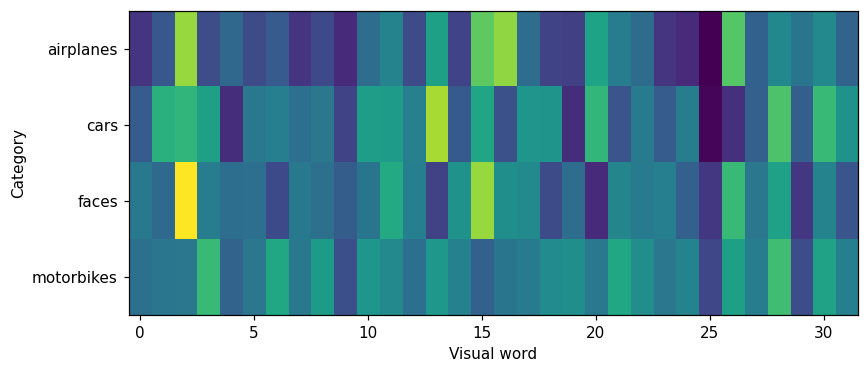

              precision    recall  f1-score   support

   airplanes       0.79      0.68      0.73        40
        cars       0.74      0.78      0.76        40
       faces       0.85      0.72      0.78        40
  motorbikes       0.62      0.78      0.69        40

    accuracy                           0.74       160
   macro avg       0.75      0.74      0.74       160
weighted avg       0.75      0.74      0.74       160



In [11]:
fig, axis = plt.subplots(figsize=(8, 3.5))
means = np.stack(
    [
        features[train_ids][labels[train_ids] == label].mean(0)
        for label in range(len(names))
    ]
)
axis.imshow(means, aspect="auto", cmap="viridis")
axis.set_yticks(range(len(names)), names)
axis.set(xlabel="Visual word", ylabel="Category")
fig.tight_layout()
fig.savefig(output / "histograms.png", dpi=140)
plt.show()
print(
    classification_report(
        labels[test_ids],
        fitted["visual_words"].predict(features[test_ids]),
        target_names=names,
        zero_division=0,
    )
)
results = {"comparisons": rows, "images": len(images), "vocabulary_size": 32}

## Reading the result

The comparison measures this particular image subset. BoW has no explicit layout, and the pixel baseline is sensitive to alignment. K-means assignments are fitted without test images, which keeps representation learning inside the development split.

In [13]:
result_path = root / "results" / "03_visual_words.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/03_visual_words.json


## Next experiment

Add a spatial pyramid with separate histograms for quadrants. Keep the train and test image identities unchanged, then compare the additional dimensionality and the validation score.

## Sources

UniPd Computer Vision and Cognitive Systems: uploaded filtering, SIFT, BoW, MLP and CNN notebooks. [scikit-learn MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.